## Student Name: Gabriel Espinoza Rojas

## Student ID: 22176691

# Task 1

## a) Modify your Multinomial Naïve Bayes (MNB) classifier from Etivity5, Task 2, to train and test a sentiment classifier.  [0.5 mark]

<b>Expected Output:</b>

```
posCount=?
negCount=?

probPos=?   probNeg=?

pos_BOW= {...}
neg_BOW= {...}

V = {...}
|V| = ?

----------------------------------------------------
Test document=('Great disappointment indeed', '?')

word= "great              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "disappointment      ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "indeed              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?

docProbPos=?              docProbNeg=?
Inferred class=?
```

In [1]:
# Using professor's shared notebook to hopefully reduce deviations with peers for this new e-tivity

import math
from collections import Counter

def naiveBayesClassifier(trainingSet,testSet):

    megaDocGB , megaDocIE = '' , ''
    GBcount , IEcount = 0 , 0

    for docClassPair in trainingSet:
        if docClassPair[1] == "GB":
            megaDocGB = megaDocGB + str.casefold(docClassPair[0]) + " "
            GBcount = GBcount +1
        if docClassPair[1] == "IE":
            megaDocIE = megaDocIE + str.casefold(docClassPair[0]) + " "
            IEcount = IEcount + 1

    print (f'megaDocGB= {megaDocGB}\nmegaDocIE= {megaDocIE}\n')

    probGB = GBcount/len(trainingSet)
    probIE = IEcount/len(trainingSet)
    print (f'probGB= {probGB} probIE= {probIE}\n')

    vocab , GB_BOW , IE_BOW = {} , {}, {}
    for word in megaDocGB.split():
        if GB_BOW.get(word):
            GB_BOW[word] = GB_BOW[word] + 1
        else:
            GB_BOW[word] = 1

    for word in megaDocIE.split():
        if IE_BOW.get(word):
            IE_BOW[word] = IE_BOW[word] + 1
        else:
            IE_BOW[word] = 1

    print (f'GB_BOW= {GB_BOW}\nIE_BOW= {IE_BOW}\n')
    vocab =  dict( Counter(GB_BOW) + Counter(IE_BOW) ) #Python Counter class is part of Collections module.
    #Counter is a subclass of Dictionary and used to keep track of elements and their frequencies.
    vocabSize =len(vocab)
    print (f'V = {vocab}\n|V| = {vocabSize}\n')

    for docClassPair in testSet:
        print (f'----------------------------------------------------\nTest document={docClassPair}\n')
        docProbGB = probGB
        docProbIE = probIE

        for word in docClassPair[0].split():

            word = str.casefold(word) # Whatever normalisation applied in the training phase must also be applied HERE

            if word not in vocab:
                print (f'word= "{word:20}",\t wordConditionalProbGB= N/A,\t wordConditionalProbIE= "N/A"')
            else:
                wordConditionalProbGB = 0
                if GB_BOW.get(word):
                    wordConditionalProbGB = (GB_BOW.get(word) + 1) / (len(megaDocGB.split()) + vocabSize)
                else:
                    wordConditionalProbGB = (0                + 1) / (len(megaDocGB.split()) + vocabSize)
                docProbGB = docProbGB * wordConditionalProbGB

                wordConditionalProbIE = 0
                if IE_BOW.get(word):
                    wordConditionalProbIE = (IE_BOW.get(word) + 1) / (len(megaDocIE.split()) + vocabSize)
                else:
                    wordConditionalProbIE = (0                + 1) / (len(megaDocIE.split()) + vocabSize)
                docProbIE = docProbIE * wordConditionalProbIE

                print (f'word= "{word:20}",\t wordConditionalProbGB= {wordConditionalProbGB},\t wordConditionalProbIE= {wordConditionalProbIE}')


        print (f'\ndocProbGB={docProbGB:10f},\t docProbIE={docProbIE:10f}')

        # rounding errors accumulate and math operations introduce tiny errros, e.g.  print(0.1 + 0.2 == 0.3)   # False
        if math.isclose(docProbIE, docProbGB, abs_tol=0.0000000000001): #abs_tol = The minimum absolute tolerance # 0.000,000,001 = 1 × 10⁻⁹ = 1e-9 = 1 billionth
            print('Inferred class= IE,GB')
        elif docProbIE>docProbGB:
            print('Inferred class= IE')
        else:
            print('Inferred class= GB')

In [2]:
def multinomialNaiveBayesClassifier(trainingSet,testSet):
    print("YOUR CODE HERE")


trainingSet = [('Boxing scene was a disappointment','-'),
               ('No plot twists or great scenes','-'),
               ('Great satire and great plot twists','+'),
               ('Great scenes a great film','+')]

testSet = [('Great disappointment indeed','?')]
multinomialNaiveBayesClassifier(trainingSet,testSet)

YOUR CODE HERE


## b) Copy your solution for (a) into a new code cell.  Modify your code to optimise it for the task of sentiment analysis, i.e., change your classification algorithm from MNB to BMNB (Binary Multinomial Naïve Bayes). [2 marks]

<b>Expected Output:</b>

```
posCount=?
negCount=?

probPos=?   probNeg=?

pos_BOW= {...}
neg_BOW= {...}

V = {...}
|V| = ?

----------------------------------------------------
Test document=('Great disappointment indeed', '?')

word= "great              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "disappointment      ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "indeed              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?

docProbPos=?              docProbNeg=?
Inferred class=?
```

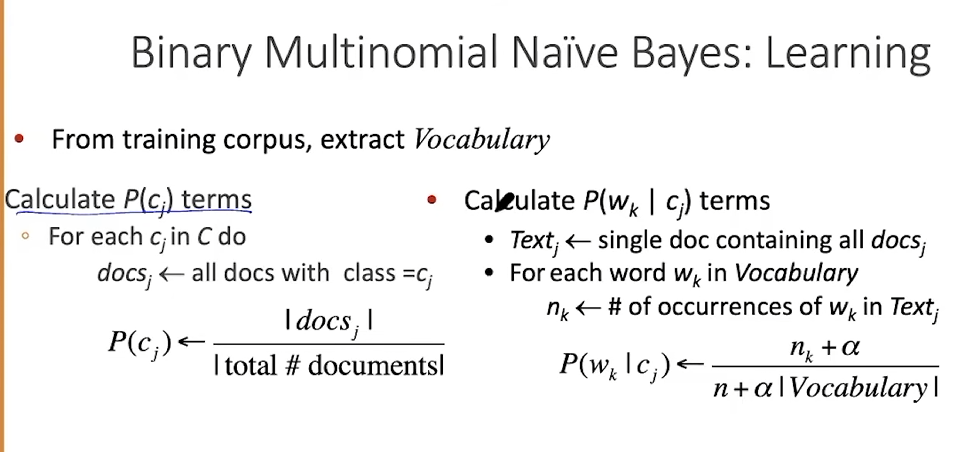

In [3]:
# Dan video about Binary NB https://youtu.be/tjDceq0qH10?list=PLAUFqkTvH_MQ&t=318

def binaryMultinomialNaiveBayesClassifier(trainingSet,testSet):
    print("YOUR CODE HERE")


trainingSet = [('Boxing scene was a disappointment','-'),
               ('No plot twists or great scenes','-'),
               ('Great satire and great plot twists','+'),
               ('Great scenes a great film','+')]

testSet = [('Great disappointment indeed','?')]

binaryMultinomialNaiveBayesClassifier(trainingSet,testSet)

YOUR CODE HERE


## c) Copy your solution for (b) into a new code cell.  Enhance your code to measure the performance of the BMNB classifier in terms of accuracy, precision, recall, and F1. [1.5 marks]

<b>Expected Output:</b>

```
posCount= ?
negCount= ?

probPos= ? probNeg= ?

pos_BOW= ?
neg_BOW= ?

V = ?
|V| = ?

----------------------------------------------------
Test document=('Great disappointment indeed', '-')


word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?
word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?
word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?


docProbPos=            ?,	 docProbNeg=            ?
Inferred class= ?
----------------------------------------------------

[... results for 8 additional test documents to appear here ...]

----------------------------------------------------
Test document=('nice film', '+')

word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?
word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?

docProbPos=            ?,	 docProbNeg=            ?
Inferred class= ?
----------------------------------------------------

TP= ?	 TN= ?
FP= ?	 FN= ?

Accuracy= ?

Precision= ?

Recall= ?

F1= ?
```

In [4]:
def binaryMultinomialNaiveBayesClassifier(trainingSet,testSet):
    print("YOUR CODE HERE")


trainingSet = [('Boxing scene was a disappointment','-'),
               ('No plot twists or great scenes','-'),
               ('Great satire and great plot twists','+'),
               ('Great scenes a great film','+')]


testSet = [('Great disappointment indeed','-'), 
           ('What a great movie','+'), 
           ('Great satire','+'), 
           ('No plot twists or satire','-'), 
           ('This movie was a disappointment','-'), 
           ('great disappointment','-'), 
           ('great boxing scenes','+'), 
           ('great movie','+'), 
           ('bad film','-'), 
           ('nice film','+')]


binaryMultinomialNaiveBayesClassifier(trainingSet,testSet)

YOUR CODE HERE


video About F1 and other metrics... https://youtu.be/mjOgb4T7yyo?list=PLAUFqkTvH_MQ&t=16 
https://youtu.be/mjOgb4T7yyo?list=PLAUFqkTvH_MQ&t=667

different video: we can use the confusion matrix to calculate R, P and F1 too:
https://youtu.be/NjhVTN19JDI?list=PLAUFqkTvH_MQ&t=132

# Task 2

Write a Sentiment Analysis function that takes a string as input and identifies its sentiment using the [TextBlob library](https://textblob.readthedocs.io/en/dev/quickstart.html#sentiment-analysis). Pay attention to the sentiment of the last two test cases.

<b>Expected Output:</b>

```
String= NLP is cool

Sentiment(polarity=0.35, subjectivity=0.65)
Positive sentiment 😊
Subjectivity: 0.65
---------------------------------

String= NLP is cool and useful

Sentiment(polarity=0.32499999999999996, subjectivity=0.325)
Positive sentiment 😊
Subjectivity: 0.325
---------------------------------

String= NLP is hard

Sentiment(polarity=-0.2916666666666667, subjectivity=0.5416666666666666)
Negative sentiment 😞
Subjectivity: 0.5416666666666666
---------------------------------

String= NLP is hard and useless

Sentiment(polarity=-0.39583333333333337, subjectivity=0.37083333333333335)
Negative sentiment 😞
Subjectivity: 0.37083333333333335
---------------------------------

String= NLP stands for Natural Language Processing

Sentiment(polarity=0.1, subjectivity=0.4)
Neutral sentiment 😐 (pay attention to this)
Subjectivity: 0.4
---------------------------------

String= NLP stands for Natural Language Processing and it can be hard sometimes

Sentiment(polarity=-0.09583333333333334, subjectivity=0.4708333333333333)
Neutral sentiment 😐 (pay attention to this)
Subjectivity: 0.4708333333333333
---------------------------------
```


In [ ]:
#Taken from previous e-tivity
import pandas as pd

!wget http://ptrckprry.com/course/ssd/data/positive-words.txt   #Opinion Lexicon: Positive Words; source: http://www.cs.uic.edu/~liub/FBS/sentiment-analysis.html
!wget http://ptrckprry.com/course/ssd/data/negative-words.txt   #Opinion Lexicon: Negative Words; source: http://www.cs.uic.edu/~liub/FBS/sentiment-analysis.html

filePath1 = "/content/positive-words.txt"
filePath2 = "/content/negative-words.txt"

#Latin-1 (ISO-8859-1) character set. Use chardet lib if needed.
#skiprows drops the licence header at the top of each file.
posWords_df = pd.read_csv(filePath1, sep='\t', header=None, names=['words'], encoding='latin-1', skiprows=[i for i in range(0,34)])
negWords_df = pd.read_csv(filePath2, sep='\t', header=None, names=['words'], encoding='latin-1', skiprows=[i for i in range(0,34)])

print(f'Number of posWords: {len(posWords_df)}   Number of negWords: {negWords_df.size}')
display(posWords_df.head(10))
display(negWords_df.head(10))

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 20630  100 20630    0     0   164k      0 --:--:-- --:--:-- --:--:--  165k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 46299  100 46299    0     0   441k      0 --:--:-- --:--:-- --:--:--  443k
Number of posWords: 2006 Number of negWords: 4783


,words
0,a+
1,abound
2,abounds
3,abundance
4,abundant
5,accessable
6,accessible
7,acclaim
8,acclaimed
9,acclamation


,words
0,2-faced
1,2-faces
2,abnormal
3,abolish
4,abominable
5,abominably
6,abominate
7,abomination
8,abort
9,aborted


In [32]:
# The base for this code was taken from previous e-tivity
from textblob import TextBlob

def sentimentAnalyzer(string):
    """
    Rule-based sentiment using TextBlob.sentiment
    'The sentiment property returns a namedtuple of the form Sentiment(polarity, subjectivity)'
    """
    
    print(f"\nstring= {string}\n")

    testimonial = TextBlob(string)

    print(f"{testimonial.sentiment}")
    
    # The polarity score is a float within the range [-1.0, 1.0]. 
    polarity = testimonial.sentiment.polarity

    # The subjectivity is a float within the range [0.0, 1.0] where 0.0 is very objective and 1.0 is very subjective.
    subjectivity = testimonial.sentiment.subjectivity

    # If math.isclose(polarity, 0) and math.isclose(subjectivity, 0.5) → neutral
    if  0.1 >= polarity >= -0.9 and 0.5 >= subjectivity >= 0.4:
        # I'll need to come back to this  
        print(f"neutral sentiment 😶")
    else:
        # If positive appearances > negative appearances → positive sentiment 
        if polarity > 0:
            print(f"Positive sentiment 🥹")
        else:
            # and vice versa
            print(f"Negative sentiment 😞")
            # emojis taken from: https://www.webfx.com/tools/emoji-cheat-sheet/
    
    print(f"Subjectivity: {subjectivity}")
    
    print("--------------------------------")

sentimentAnalyzer("NLP is cool")
sentimentAnalyzer("NLP is cool and useful")
sentimentAnalyzer("NLP is hard")
sentimentAnalyzer("NLP is hard and useless")
sentimentAnalyzer("NLP stands for Natural Language Processing")
sentimentAnalyzer("NLP stands for Natural Language Processing and it can be hard sometimes")


string= NLP is cool

Sentiment(polarity=0.35, subjectivity=0.65)
Positive sentiment 🥹
Subjectivity: 0.65
--------------------------------

string= NLP is cool and useful

Sentiment(polarity=0.32499999999999996, subjectivity=0.325)
Positive sentiment 🥹
Subjectivity: 0.325
--------------------------------

string= NLP is hard

Sentiment(polarity=-0.2916666666666667, subjectivity=0.5416666666666666)
Negative sentiment 😞
Subjectivity: 0.5416666666666666
--------------------------------

string= NLP is hard and useless

Sentiment(polarity=-0.39583333333333337, subjectivity=0.37083333333333335)
Negative sentiment 😞
Subjectivity: 0.37083333333333335
--------------------------------

string= NLP stands for Natural Language Processing

Sentiment(polarity=0.1, subjectivity=0.4)
neutral sentiment 😶
Subjectivity: 0.4
--------------------------------

string= NLP stands for Natural Language Processing and it can be hard sometimes

Sentiment(polarity=-0.09583333333333334, subjectivity=0.47083333333

# Task 3

Write a Python code snippet to:
1. Download the BBC text classification dataset from https://storage.googleapis.com/dataset-uploader/bbc/bbc-text.csv

2. Explore the dataset and print out: 

    a. The total number of documents in the dataset
    
    b. The total number of documents per class (is the dataset balanced?)
    
    c. One sample document per class 
[1 mark]

3. Split the data into training and test sets (**80/20** training/test split) using your own <code>train_test_split()</code> Function.

4. Use the [textblob.classifiers](https://textblob.readthedocs.io/en/dev/classifiers.html) module to train and test a Naive Bayes classifier and print out the model’s accuracy. [1.5 marks]

5. Re-evaluate the model using 2-fold cross-validation. [1.5 marks]

Note 1: Given the relatively large size of the BBC dataset, the training and testing process could take a few minutes. In case of experiencing an out-of-memory error (after multiple runs), restart your VM (Runtime -> Restart Session).

Note 2: You can first develop and test your code using a small subset of the dataset (e.g. 100 docs). Once you are happy with the results, proceed to using the full dataset for one last run.


## 1. Download the BBC text classification dataset

In [6]:
# load dataset
import pandas as pd

!wget https://storage.googleapis.com/download.tensorflow.org/data/bbc-text.csv

filePath1 = "/content/bbc-text.csv"

df = pd.read_csv(filePath1)

--2026-10-21 20:51:28--  https://storage.googleapis.com/download.tensorflow.org/data/bbc-text.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 172.253.62.207, 172.253.115.207, 172.253.122.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.253.62.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5057493 (4.8M) [text/csv]
Saving to: ‘bbc-text.csv.2’

bbc-text.csv.2      100%[===================>]   4.82M  --.-KB/s    in 0.02s   

2026-10-21 20:51:28 (235 MB/s) - ‘bbc-text.csv.2’ saved [5057493/5057493]



## 2. Explore the dataset and print out: 

    

### a. The total number of documents in the dataset

In [7]:
print(f'Total number of ocuments in the dataset: {len(df)}')

Total number of ocuments in the dataset: 2225


### b. The total number of documents per class (is the dataset balanced?)

,category,text
count,2225,2225
unique,5,2126
top,sport,blind student hears in colour a blind studen...
freq,511,2


Count for category tech 401
Count for category business 510
Count for category sport 511
Count for category entertainment 386
Count for category politics 417


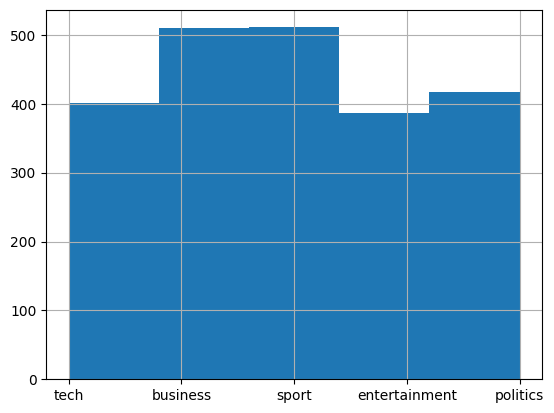

In [8]:
# Print statistical summary for all numerical attributes
display(df.describe())

(df['category'].hist(bins=5))

print(f"Count for category tech {(df['category'] == 'tech').sum()}")
print(f"Count for category business {(df['category'] == 'business').sum()}")
print(f"Count for category sport {(df['category'] == 'sport').sum()}")
print(f"Count for category entertainment {(df['category'] == 'entertainment').sum()}")
print(f"Count for category politics {(df['category'] == 'politics').sum()}")


I used described to see how many unique categories the dataset has. I'd say it is balanced.

### c. One sample document per class 

In [ ]:
print(f"Sample document for class tech:\n\"{(df.loc[df['category'] == 'tech']).values[0][1]}\"")
print(f"Sample document for class business:\n\"{(df.loc[df['category'] == 'business']).values[0][1]}\"")
print(f"Sample document for class sport:\n\"{(df.loc[df['category'] == 'sport']).values[0][1]}\"")
print(f"Sample document for class entertainment:\n\"{(df.loc[df['category'] == 'entertainment']).values[0][1]}\"")
print(f"Sample document for class politics:\n\"{(df.loc[df['category'] == 'politics']).values[0][1]}\"")

Sample document for class tech:
"tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in five years  time.  that is according to an expert panel which gathered at the annual consumer electronics show in las vegas to discuss how these new technologies will impact one of our favourite pastimes. with the us leading the trend  programmes and other content will be delivered to viewers via home networks  through cable  satellite  telecoms companies  and broadband service providers to front rooms and portable devices.  one of the most talked-about technologies of ces has been digital and personal video recorders (dvr and pvr). these set-top boxes  like the us s tivo and the uk s sky+ system  allow people to record  store  play  pause and forward wind tv programmes when they want.  essentially  the technology allows for much more personalised tv. they

## 3. Split the data into training and test sets (**80/20** training/test split) using your own <code>train_test_split()</code> Function.


In [10]:
def train_test_split(samples):
    """
    My own implementation of the famous function from scikit learn (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
    """
    
    X_train, y_test = [], []

    X_train = df.values[:(len(df)//20)]
    y_test = df.values[(len(df)//20):]

    print(f"size of training set: {len(X_train)}, size of testing set: {len(y_test)}")

    return X_train, y_test 

X_train_T3, y_test_T3 = train_test_split(df)

size of training set: 111, size of testing set: 2114


## 4. Use the [textblob.classifiers](https://textblob.readthedocs.io/en/dev/classifiers.html) module to train and test a Naive Bayes classifier and print out the model’s accuracy. [1.5 marks]

In [11]:
from textblob.classifiers import NaiveBayesClassifier

classifier = NaiveBayesClassifier(X_train_T3)

classifier.accuracy(y_test_T3)

0.0004730368968779565

## 5. Re-evaluate the model using 2-fold cross-validation. [1.5 marks]

In [17]:
# scikit-learn k-fold cross-validation (https://machinelearningmastery.com/k-fold-cross-validation/)
from numpy import array
from sklearn.model_selection import KFold

# prepare cross validation
kfold = KFold(2)
# enumerate splits
for train, test in kfold.split(df):
	print('train: %s, test: %s' % (len(df.values[train]), len(df.values[test])))

	classifier = NaiveBayesClassifier(df.values[train])
	accuracy = classifier.accuracy(df.values[test])
	print("Accuracy ", accuracy)

train: 1112, test: 1113
Accuracy  0.0
train: 1113, test: 1112
Accuracy  0.0


# Task 4 

Write a function that takes sets of training and test documents as input and uses the [textblob.classifiers](https://textblob.readthedocs.io/en/dev/classifiers.html) module to:

 a) train a Naive Bayes classifier using the provided training set.

 b) evaluate the performance of the model and print its accuracy. 

 c***) explain why the class of the last test document is predicted to be “GB” or “Ireland”. Write your answer in a text cell in your notebook. 

[1 mark]

**Expected Output:**
```
document: ('University of Limerick', 'IE')		 predicted class: IE

 document: ('University College Dublin', 'IE')		 predicted class: IE

 document: ('Imperial College London', 'GB')		 predicted class: GB

 document: ('University of Oxford', 'GB')		 predicted class: GB

 document: ('Ireland & GB', 'IE')		 predicted class: ?

 Accuracy: ?
```

***Although rewarding, some could find this investigation challenging. The below resources should help you find the right path:

1. Textblob uses the NLTK library under the hood, so that's where you should start your investigation, i.e. **nltk.classify.naivebayes** module

2. Take a look at the [[docs]](https://www.nltk.org/api/nltk.classify.naivebayes.html#nltk.classify.naivebayes.NaiveBayesClassifier.classify) and [[source]](https://www.nltk.org/_modules/nltk/classify/naivebayes.html#NaiveBayesClassifier.classify) of **classify(self, featureset)** method in the **naivebayes module.** Pay attention to what this method returns. This should lead you to **prob_classify(self, featureset)** method.

3. Review prob_classify(self, featureset) [[docs]](https://www.nltk.org/api/nltk.classify.naivebayes.html#nltk.classify.naivebayes.NaiveBayesClassifier.prob_classify) and [[source]](https://www.nltk.org/_modules/nltk/classify/naivebayes.html#NaiveBayesClassifier.prob_classify). **Pay attention to what this method returns.** This should lead you to **class nltk.probability.DictionaryProbDist**

4. Review the  [[docs]](https://www.nltk.org/api/nltk.probability.html#nltk.probability.DictionaryProbDist) and [[source]](https://www.nltk.org/_modules/nltk/probability.html#DictionaryProbDist) for class **nltk.probability.DictionaryProbDist**. This should lead you to the **max()** method in this class.

5. Review the [[docs]](https://www.nltk.org/api/nltk.probability.html#nltk.probability.DictionaryProbDist.max) and [[source]](https://www.nltk.org/_modules/nltk/probability.html#DictionaryProbDist.max) of **max()** method. You have now arrived at the source of the issue. 


Food for thought: would you modify the **nltk.classify.naivebayes module** to better deal with these cases and if so, how?


## a) train a Naive Bayes classifier using the provided training set.

In [ ]:
import nltk
# extra requirement to download punkt
!python -m textblob.download_corpora
nltk.download('punkt')
from textblob.classifiers import NaiveBayesClassifier


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package conll2000 to /root/nltk_data...
[nltk_data]   Unzipping corpora/conll2000.zip.
[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.
Finished.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [ ]:
# from core material (practice) https://textblob.readthedocs.io/en/dev/classifiers.html#classifying-textblobs

def naiveBayesClassifier(trainingSet,testSet):
    classifier = NaiveBayesClassifier(trainingSet)

    for document in testSet:
        print(f"document: {document}		 predicted class: {classifier.classify(document[0])}")


trainingSet = [('London is the Capital of GB','GB'),
               ('Oxford is a city in GB','GB'),
               ('Dublin is the capital of Ireland','IE'),
               ('Limerick is a city in Ireland','IE')]
testSet = [('University of Limerick','IE'),
           ('University College Dublin','IE'),
           ('Imperial College London','GB'),
           ('University of Oxford','GB'),
           ('Ireland & GB','IE')]

naiveBayesClassifier(trainingSet,testSet)

document: ('University of Limerick', 'IE')		 predicted class: IE
document: ('University College Dublin', 'IE')		 predicted class: IE
document: ('Imperial College London', 'GB')		 predicted class: GB
document: ('University of Oxford', 'GB')		 predicted class: GB
document: ('Ireland & GB', 'IE')		 predicted class: IE


## b) evaluate the performance of the model and print its accuracy. 

$$accuracy = \frac{tp+tn}{tp+fp+tn+fn}$$

In [ ]:
total_pos = 3
total_neg = 2
false_pos = 0
false_neg = 0

def accuracy(total_pos, total_neg, false_pos, false_neg):
    return (total_pos + total_neg)/(total_pos + false_pos + total_neg + false_neg)

print(f"Accuracy: {accuracy(total_pos, total_neg, false_pos, false_neg)}")

Accuracy: 1.0


 ## c) explain why the class of the last test document is predicted to be “GB” or “Ireland”. Write your answer in a text cell in your notebook. 